# E-commerce orders and transactions: exploratory data analysis

This notebook explores the local `ecommerce_orders_transactions_2026.csv` file. It checks data quality, summarizes sales and profitability, and compares trends across time, products, customers, regions, and operations. Values are not assumed in advance; inspect the outputs before drawing conclusions.

> Sales metrics below use the dataset's provided fields. The row-level structure may be order-line or transaction-level, so order counts use distinct `Order_ID` values where relevant.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

DATA_FILE = Path("ecommerce_orders_transactions_2026.csv")
if not DATA_FILE.exists():
    matches = list(Path.cwd().glob("**/ecommerce_orders_transactions_2026.csv"))
    if not matches:
        raise FileNotFoundError("Could not find ecommerce_orders_transactions_2026.csv under the notebook's working directory.")
    DATA_FILE = matches[0]

df = pd.read_csv(DATA_FILE, low_memory=False)
print(f"Loaded {DATA_FILE.resolve()}")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
display(df.head())

Loaded C:\Users\sulaiman.at\Documents\GitHub\E-commerce-Analytics\ecommerce_orders_transactions_2026.csv
Shape: 200,000 rows x 50 columns


,Order_ID,Order_Date,Order_Time,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Customer_Country,Customer_Continent,Customer_City,Customer_Region,Customer_Segment,Product_ID,SKU,Product_Name,Product_Category,Product_Subcategory,Brand,Quantity,Unit_Price_USD,Gross_Sales_USD,Discount_Percentage,Discount_Amount_USD,Net_Sales_USD,Tax_Rate_Percentage,Tax_USD,Shipping_Cost_USD,Total_Order_Value_USD,Payment_Method,Payment_Status,Order_Status,Shipping_Method,Delivery_Days,Return_Status,Return_Reason,Marketing_Channel,Device_Type,Coupon_Used,Coupon_Code,Customer_Rating,Review_Sentiment,Is_Repeat_Customer,Sales_Region,Warehouse,Supplier,Order_Profit_USD,Profit_Margin_Percentage,Is_Bestseller_Product,Is_New_Customer,Is_First_Order
0,ORD-105927,2026-02-10,11:34:55,CUST-000001,Mateo Park,65,Male,Canada,North America,Vancouver,British Columbia,Premium Customer,PROD-006035,HEAL-CEN-6035,Ultra Centrum Medical Devices 6035,Health & Wellness,Medical Devices,Centrum,3,45.78,137.34,20.00,27.47,109.87,10.00,10.99,59.30,180.16,Google Pay,Paid,Delivered,International,21,No Return,NaN,Organic Search,Desktop,False,NaN,3.70,Neutral,False,North America,Frankfurt,Asia Consumer Goods Ltd,-51.34,-46.73,False,False,True
1,ORD-178205,2026-02-19,10:10:49,CUST-000001,Mateo Park,65,Male,Canada,North America,Vancouver,British Columbia,Premium Customer,PROD-001611,MOBI-GOO-1611,Ultra Google Screen Protectors,Mobile Phones,Screen Protectors,Google,1,160.81,160.81,7.50,12.06,148.75,10.00,14.88,16.44,180.07,PayPal,Paid,Processing,Express,2,No Return,NaN,Email Marketing,Desktop,False,NaN,2.50,Negative,True,North America,London,International Retail Distribution,24.30,16.34,False,False,False
2,ORD-057651,2026-07-19,11:44:02,CUST-000002,Nina Wong,23,Female,New Zealand,Oceania,Auckland,Auckland,New Customer,PROD-003844,FASH-LEV-3844,Ultra Levi's Men's Clothing,Fashion,Men's Clothing,Levi's,1,278.34,278.34,10.00,27.83,250.51,15.00,37.58,9.27,297.36,Credit Card,Paid,Delivered,Standard,4,No Return,NaN,Social Media,Tablet,False,NaN,3.80,Neutral,False,Asia Pacific,Toronto,Premium Electronics Supply,64.77,25.86,False,False,True
3,ORD-124661,2026-08-26,18:13:21,CUST-000003,Aisha Moore,19,Female,Kenya,Africa,Eldoret,Mombasa,Regular Customer,PROD-003331,BOOK-HAC-3331,Pro Hachette Self-Help,Books,Self-Help,Hachette,1,86.94,86.94,15.00,13.04,73.90,16.00,11.82,8.14,93.86,Buy Now Pay Later,Paid,Delivered,Economy,8,No Return,NaN,Social Media,Tablet,False,NaN,4.90,Positive,False,Africa,Dubai,Premium Electronics Supply,9.29,12.57,False,False,True
4,ORD-162453,2026-09-08,10:34:46,CUST-000003,Aisha Moore,19,Female,Kenya,Africa,Eldoret,Mombasa,Regular Customer,PROD-006670,TOOL-MIL-6670,Luxury Milwaukee Hardware 6670,Tools & Hardware,Hardware,Milwaukee,2,73.50,147.00,25.00,36.75,110.25,16.00,17.64,22.21,150.10,Cash on Delivery,Pending,Processing,Express,3,No Return,NaN,Organic Search,Desktop,False,NaN,3.20,Neutral,True,Africa,Toronto,Global Home Supplies,-15.16,-13.75,False,False,False


## 1. Structure and data quality

Check column types, missingness, duplicate rows, and identifier cardinality before relying on any aggregation.

In [2]:
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(dropna=True),
}).sort_values(["missing_pct", "unique"], ascending=[False, True]))

print(f"Exact duplicate rows: {df.duplicated().sum():,}")
for col in ["Order_ID", "Customer_ID", "Product_ID"]:
    if col in df.columns:
        print(f"Distinct {col}: {df[col].nunique(dropna=True):,} (missing: {df[col].isna().sum():,})")

display(df.describe(include="all").T)

,dtype,non_null,missing,missing_pct,unique
Return_Reason,object,8330,191670,95.84,8
Coupon_Code,object,29835,170165,85.08,12
Return_Status,object,200000,0,0.00,2
Coupon_Used,bool,200000,0,0.00,2
Is_Repeat_Customer,bool,200000,0,0.00,2
Is_Bestseller_Product,bool,200000,0,0.00,2
Is_New_Customer,bool,200000,0,0.00,2
Is_First_Order,bool,200000,0,0.00,2
Device_Type,object,200000,0,0.00,3
Review_Sentiment,object,200000,0,0.00,3


Exact duplicate rows: 0
Distinct Order_ID: 200,000 (missing: 0)
Distinct Customer_ID: 69,728 (missing: 0)
Distinct Product_ID: 10,000 (missing: 0)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order_ID,200000,200000,ORD-105927,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Date,200000,352,2026-11-06,822,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Time,200000,67367,09:55:36,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,200000,69728,CUST-017913,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Name,200000,69728,Carlos Robinson 17912,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Age,"200,000.00",NaN,NaN,NaN,46.47,16.74,18.00,32.00,46.00,61.00,75.00
Customer_Gender,200000,4,Male,95955,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Country,200000,51,Czech Republic,4203,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Continent,200000,6,Europe,74381,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_City,200000,208,Doha,3914,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Prepare analysis fields

Convert dates and numeric measures explicitly. Invalid parsed values become missing and should be considered when interpreting results.

In [3]:
if "Order_Date" in df.columns:
    df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")

numeric_candidates = [
    "Customer_Age", "Quantity", "Unit_Price_USD", "Gross_Sales_USD",
    "Discount_Percentage", "Discount_Amount_USD", "Net_Sales_USD",
    "Tax_Rate_Percentage", "Tax_USD", "Shipping_Cost_USD",
    "Total_Order_Value_USD", "Delivery_Days", "Customer_Rating",
    "Order_Profit_USD", "Profit_Margin_Percentage",
]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if "Order_Date" in df.columns:
    df["Order_Month"] = df["Order_Date"].dt.to_period("M").dt.to_timestamp()

available_measures = [col for col in numeric_candidates if col in df.columns]
display(df[available_measures].describe().T)
if "Order_Date" in df.columns:
    print(f"Parsed order dates: {df['Order_Date'].notna().sum():,} / {len(df):,}")
    print(f"Date range: {df['Order_Date'].min()} to {df['Order_Date'].max()}")

,count,mean,std,min,25%,50%,75%,max
Customer_Age,"200,000.00",46.47,16.74,18.00,32.00,46.00,61.00,75.00
Quantity,"200,000.00",2.10,1.18,1.00,1.00,2.00,3.00,5.00
Unit_Price_USD,"200,000.00",285.85,377.00,5.00,50.02,93.76,348.42,"1,499.28"
Gross_Sales_USD,"200,000.00",600.89,970.30,5.00,79.25,199.38,672.31,"7,494.35"
Discount_Percentage,"200,000.00",12.03,10.34,0.00,5.00,10.00,20.00,40.00
Discount_Amount_USD,"200,000.00",72.19,164.84,0.00,2.67,15.46,61.29,"2,988.22"
Net_Sales_USD,"200,000.00",528.70,861.97,3.30,68.67,177.40,584.84,"7,494.35"
Tax_Rate_Percentage,"200,000.00",15.69,6.74,0.00,10.00,17.00,21.00,27.00
Tax_USD,"200,000.00",82.91,151.31,0.00,8.73,25.13,83.11,"1,875.92"
Shipping_Cost_USD,"200,000.00",15.79,10.55,3.00,8.68,13.34,18.84,60.00


Parsed order dates: 200,000 / 200,000
Date range: 2026-01-01 00:00:00 to 2026-12-31 00:00:00


## 3. Top-level business metrics

Revenue, order value, and profit fields are kept distinct: for example, `Net_Sales_USD` is not interchangeable with `Total_Order_Value_USD`. Validate each field's definition against the source data documentation before external reporting.

In [4]:
def available_sum(column):
    return df[column].sum(min_count=1) if column in df.columns else np.nan

kpis = {
    "Rows": len(df),
    "Distinct orders": df["Order_ID"].nunique(dropna=True) if "Order_ID" in df.columns else np.nan,
    "Distinct customers": df["Customer_ID"].nunique(dropna=True) if "Customer_ID" in df.columns else np.nan,
    "Net sales (USD)": available_sum("Net_Sales_USD"),
    "Total order value (USD)": available_sum("Total_Order_Value_USD"),
    "Order profit (USD)": available_sum("Order_Profit_USD"),
    "Average net sales per row (USD)": df["Net_Sales_USD"].mean() if "Net_Sales_USD" in df.columns else np.nan,
    "Average order value (USD)": (
        df.groupby("Order_ID", dropna=True)["Total_Order_Value_USD"].sum().mean()
        if {"Order_ID", "Total_Order_Value_USD"}.issubset(df.columns) else np.nan
    ),
}
display(pd.Series(kpis, name="Value").to_frame())

if "Order_Status" in df.columns:
    display(df["Order_Status"].value_counts(dropna=False).rename_axis("Order_Status").to_frame("rows"))

,Value
Rows,"200,000.00"
Distinct orders,"200,000.00"
Distinct customers,"69,728.00"
Net sales (USD),"105,739,089.34"
Total order value (USD),"125,478,421.59"
Order profit (USD),"30,494,093.62"
Average net sales per row (USD),528.70
Average order value (USD),627.39


,rows
Order_Status,
Delivered,140112
Processing,19887
Shipped,15987
Cancelled,12019
Returned,11995


## 4. Sales and profitability distributions

Inspect skew and outliers in key numeric measures. The box plots use a robust display range (1st–99th percentile) while the full distributions remain summarized above.

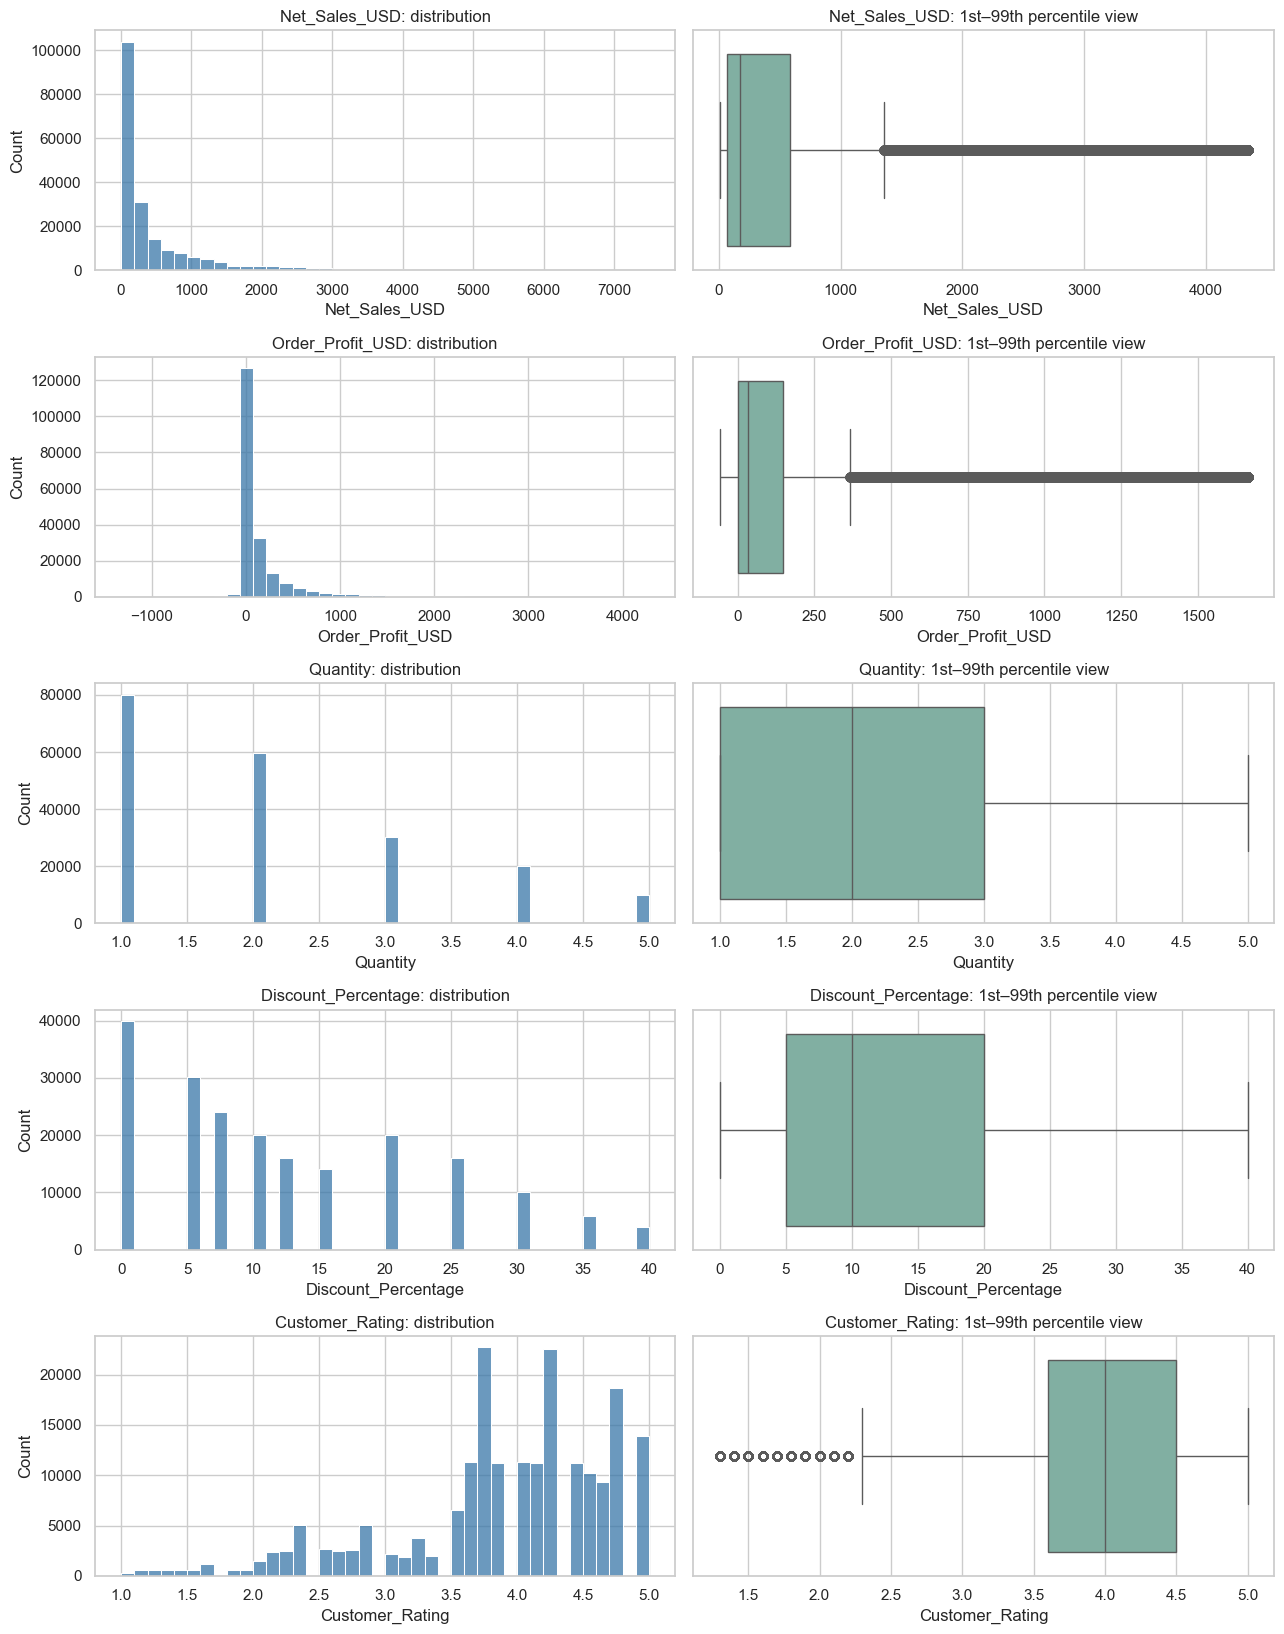

In [5]:
distribution_cols = [c for c in ["Net_Sales_USD", "Order_Profit_USD", "Quantity", "Discount_Percentage", "Customer_Rating"] if c in df.columns]
if distribution_cols:
    fig, axes = plt.subplots(len(distribution_cols), 2, figsize=(13, 3.3 * len(distribution_cols)))
    if len(distribution_cols) == 1:
        axes = np.array([axes])
    for row, col in enumerate(distribution_cols):
        values = df[col].dropna()
        if not values.empty:
            sns.histplot(values, bins=40, ax=axes[row, 0], color="#3977a8")
            axes[row, 0].set_title(f"{col}: distribution")
            low, high = values.quantile([0.01, 0.99])
            sns.boxplot(x=values.clip(lower=low, upper=high), ax=axes[row, 1], color="#79b7a5")
            axes[row, 1].set_title(f"{col}: 1st–99th percentile view")
    plt.tight_layout()
    plt.show()

## 5. Trends over time

Monthly totals show how sales and profit change over the date range. If data is incomplete at the start or end of the period, compare only full periods.

,orders,net_sales,profit,units
Order_Month,,,,
2026-01-01,12075,"6,426,767.06","1,880,701.45",25133
2026-02-01,11962,"6,261,321.99","1,794,093.94",25168
2026-03-01,13959,"7,411,058.04","2,160,048.94",29201
2026-04-01,13890,"7,556,877.59","2,196,620.49",29415
2026-05-01,16277,"8,466,119.52","2,378,521.60",34141
2026-06-01,15759,"8,309,132.51","2,403,788.32",32886
2026-07-01,16108,"8,467,118.75","2,440,544.85",33815
2026-08-01,18429,"9,755,730.80","2,808,246.74",38523
2026-09-01,17788,"9,346,980.76","2,687,782.19",37398


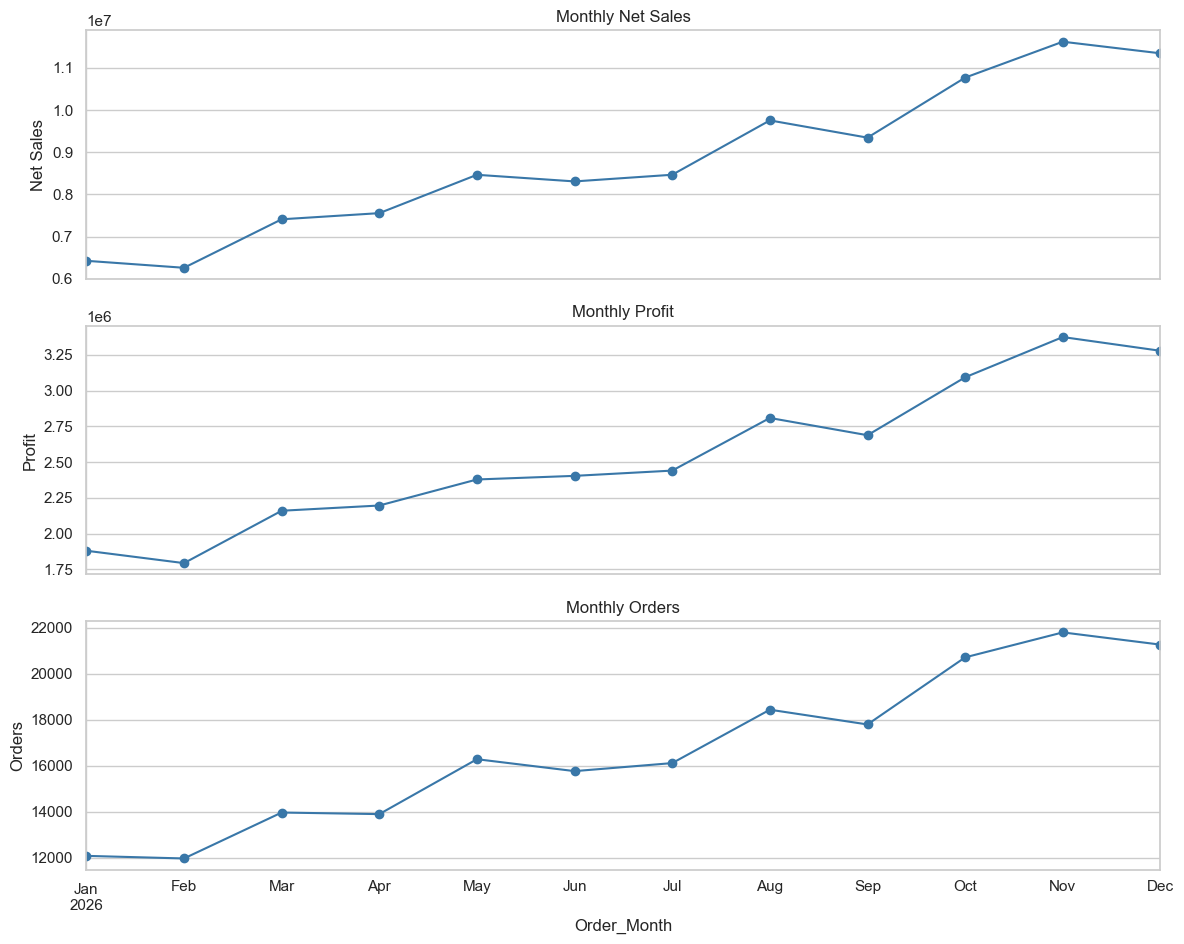

In [6]:
if {"Order_Month", "Order_ID"}.issubset(df.columns):
    monthly_spec = {"orders": ("Order_ID", "nunique")}
    for source, name in [("Net_Sales_USD", "net_sales"), ("Order_Profit_USD", "profit"), ("Quantity", "units")]:
        if source in df.columns:
            monthly_spec[name] = (source, "sum")
    monthly = df.dropna(subset=["Order_Month"]).groupby("Order_Month").agg(**monthly_spec).sort_index()
    display(monthly)
    plot_cols = [c for c in ["net_sales", "profit", "orders"] if c in monthly.columns]
    if plot_cols:
        fig, axes = plt.subplots(len(plot_cols), 1, figsize=(12, 3.2 * len(plot_cols)), sharex=True)
        axes = np.atleast_1d(axes)
        for ax, col in zip(axes, plot_cols):
            monthly[col].plot(ax=ax, marker="o", color="#3977a8")
            ax.set_title(f"Monthly {col.replace('_', ' ').title()}")
            ax.set_ylabel(col.replace("_", " ").title())
        plt.tight_layout()
        plt.show()
else:
    print("Order_Month and/or Order_ID unavailable; monthly trend analysis skipped.")

## 6. Product and category performance

Compare category and product contribution to net sales and profit. Summed sales are row-based; distinct order counts avoid counting repeated order lines as separate orders.


### Product_Category


,orders,net_sales,profit,units
Product_Category,,,,
Electronics,20577,"28,535,620.09","8,749,423.35",43181
Fashion,19664,"5,747,821.80","1,483,977.46",41045
Mobile Phones,17254,"24,628,033.91","7,843,766.57",36137
Computers & Accessories,16571,"23,146,477.00","6,970,268.92",34972
Home & Kitchen,16533,"7,902,874.57","2,243,801.78",34839
Beauty & Personal Care,13991,"1,355,817.51","190,791.41",29513
Sports & Fitness,10708,"1,049,706.72","159,302.92",22519
Furniture,10568,"4,823,933.61","1,313,614.37",22153
Books,9993,"943,343.40","140,117.03",20893


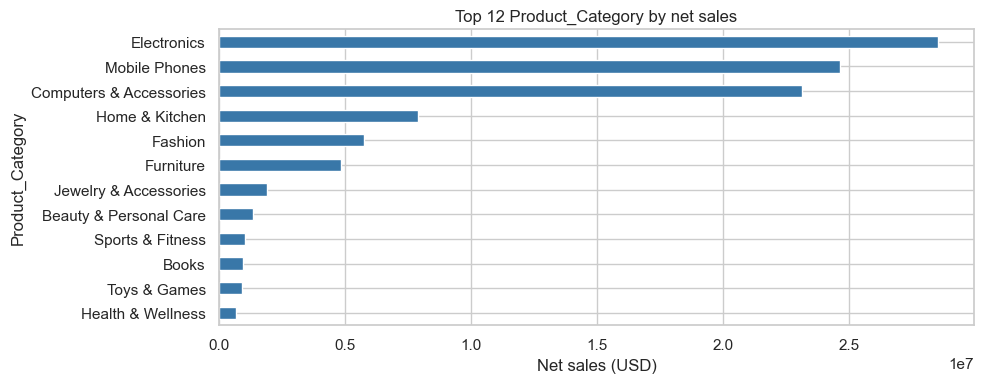


### Product_Subcategory


,orders,net_sales,profit,units
Product_Subcategory,,,,
Sportswear,4189,"858,942.67","211,502.91",8694
Screen Protectors,3089,"4,151,738.77","1,297,175.49",6553
Phone Cases,2985,"4,520,397.42","1,425,735.13",6231
Accessories,2961,"876,383.96","222,807.46",6271
Smartphones,2957,"3,724,546.57","1,203,546.30",6111
Power Banks,2919,"4,337,526.45","1,335,561.90",6057
Speakers,2866,"4,105,782.35","1,229,700.48",6072
Hair Care,2808,"278,696.21","36,507.79",5869
Chargers,2735,"4,024,554.10","1,372,451.60",5733


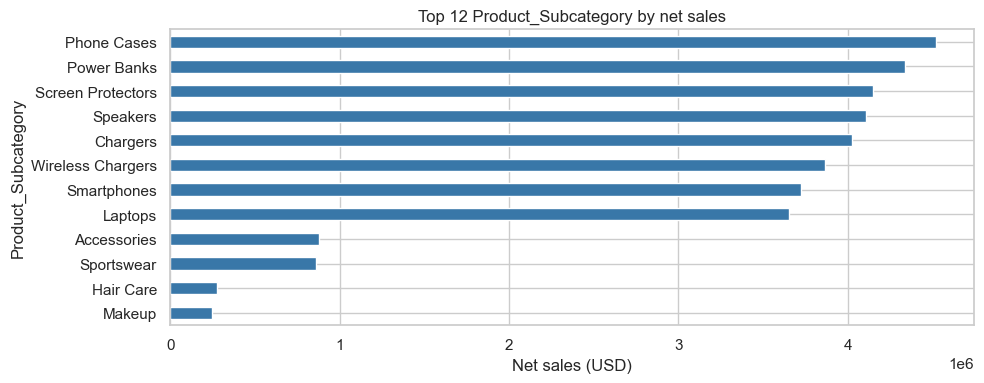


### Brand


,orders,net_sales,profit,units
Brand,,,,
Black+Decker,4421,"1,432,773.38","402,496.21",9466
IKEA,4416,"2,286,023.15","624,823.12",9275
Nike,4339,"983,318.52","229,484.20",9104
Samsung,4237,"6,034,013.40","1,849,785.50",8926
Apple,4186,"5,914,203.40","1,802,903.82",8711
Puma,3659,"786,286.36","192,054.82",7568
Adidas,3369,"721,670.13","174,452.38",7051
Sonos,2739,"3,814,201.99","1,225,800.60",5662
Dyson,2456,"1,100,262.38","293,734.73",5096


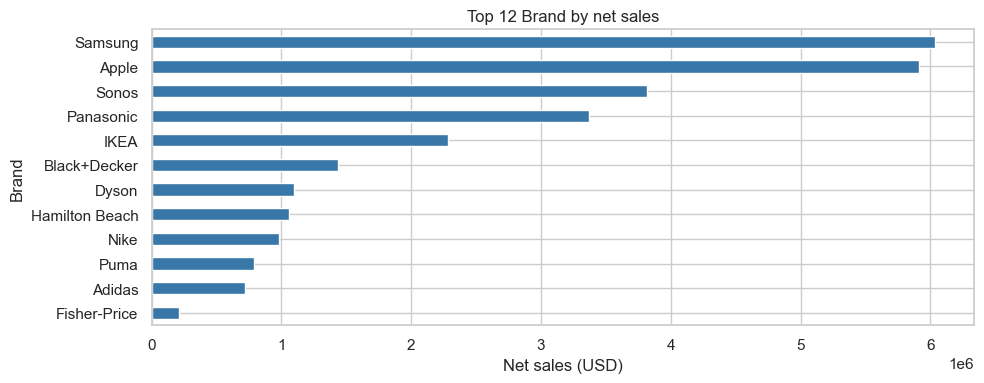


### Product_Name


,orders,net_sales,profit,units
Product_Name,,,,
Essential Lenovo Laptops,39,"54,407.96","21,873.89",85
Premium Bosch Car Electronics 2265,38,"5,942.44","2,500.28",79
Classic Lenovo Storage Devices 6381,37,"15,716.61","7,387.49",87
Essential Bridgestone Exterior Accessories,37,"6,338.24","1,460.61",87
Premium Steelcase Desks,36,"26,611.30","3,089.67",91
Smart Dove Grooming,36,"6,136.55","2,376.33",77
Classic Royal Canin Pet Food,35,"6,092.30","2,509.18",71
Classic Simon & Schuster E-Books 6030,35,"1,328.53",75.15,76
Pro Apple Power Banks 9394,35,"48,556.57","8,721.29",70


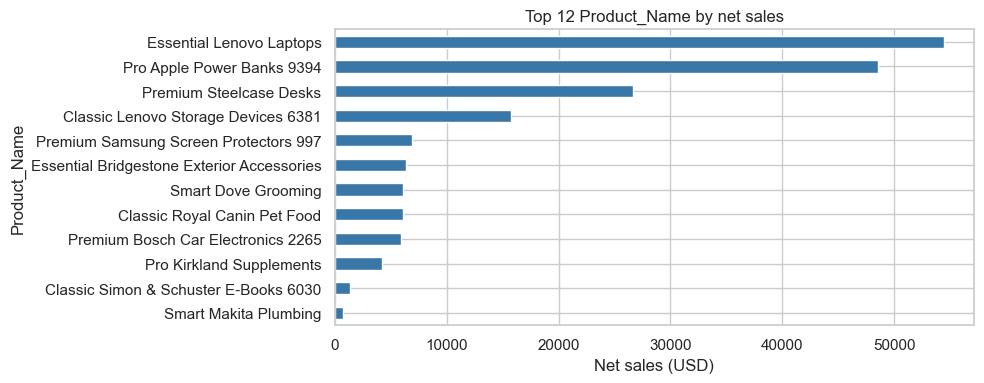

In [7]:
def grouped_performance(group_col, top_n=15):
    if group_col not in df.columns:
        print(f"{group_col} not available.")
        return
    agg = {}
    if "Order_ID" in df.columns:
        agg["orders"] = ("Order_ID", "nunique")
    for source, name in [("Net_Sales_USD", "net_sales"), ("Order_Profit_USD", "profit"), ("Quantity", "units")]:
        if source in df.columns:
            agg[name] = (source, "sum")
    if not agg:
        print("No compatible measures available.")
        return
    result = df.groupby(group_col, dropna=False).agg(**agg).sort_values(
        "net_sales" if "net_sales" in agg.values() else next(iter(agg)), ascending=False
    )
    display(result.head(top_n))
    if "net_sales" in result.columns:
        result["net_sales"].head(top_n).sort_values().plot(kind="barh", figsize=(10, max(4, top_n * 0.28)), color="#3977a8")
        plt.title(f"Top {top_n} {group_col} by net sales")
        plt.xlabel("Net sales (USD)")
        plt.tight_layout()
        plt.show()

for dimension in ["Product_Category", "Product_Subcategory", "Brand", "Product_Name"]:
    if dimension in df.columns:
        print(f"\n### {dimension}")
        grouped_performance(dimension, top_n=12)

## 7. Customer and market segments

Compare customer segment, country/region, marketing channel, and payment method. Interpret these as descriptive associations, not causal effects.

In [8]:
for dimension in ["Customer_Segment", "Customer_Continent", "Customer_Country", "Sales_Region", "Marketing_Channel", "Payment_Method", "Device_Type"]:
    if dimension not in df.columns:
        continue
    print(f"\n### {dimension}")
    agg = {}
    if "Order_ID" in df.columns:
        agg["orders"] = ("Order_ID", "nunique")
    if "Customer_ID" in df.columns:
        agg["customers"] = ("Customer_ID", "nunique")
    if "Net_Sales_USD" in df.columns:
        agg["net_sales"] = ("Net_Sales_USD", "sum")
    if "Order_Profit_USD" in df.columns:
        agg["profit"] = ("Order_Profit_USD", "sum")
    if agg:
        display(df.groupby(dimension, dropna=False).agg(**agg).sort_values(
            "net_sales" if "net_sales" in agg else next(iter(agg)), ascending=False
        ).head(15))


### Customer_Segment


,orders,customers,net_sales,profit
Customer_Segment,,,,
Regular Customer,70528,24580,"37,217,870.49","10,727,893.37"
New Customer,60267,20875,"31,921,843.43","9,211,783.12"
Premium Customer,29730,10428,"15,703,739.72","4,516,105.25"
At-Risk Customer,19387,6843,"10,348,088.45","3,017,476.50"
VIP Customer,10191,3526,"5,421,372.82","1,558,497.58"
Dormant Customer,9897,3476,"5,126,174.43","1,462,337.80"



### Customer_Continent


,orders,customers,net_sales,profit
Customer_Continent,,,,
Europe,74381,25889,"39,273,027.14","11,279,947.97"
Asia,70019,24472,"37,183,633.65","10,770,957.67"
Africa,19991,6936,"10,462,735.17","3,042,963.60"
South America,15939,5577,"8,485,069.74","2,429,915.31"
North America,11794,4088,"6,145,120.73","1,765,530.86"
Oceania,7876,2766,"4,189,502.91","1,204,778.21"



### Customer_Country


...

,orders,customers,net_sales,profit
Marketing_Channel,,,,
Referral,20091,17606,"10,650,765.85","3,052,611.85"
Direct,19962,17567,"10,613,741.46","3,038,986.97"
Display Advertising,20149,17683,"10,599,930.34","3,080,804.07"
Affiliate,19866,17435,"10,599,468.07","3,061,169.80"
Social Media,20099,17614,"10,599,040.26","3,049,546.21"
Paid Search,19995,17573,"10,557,421.59","3,069,363.90"
Organic Search,20145,17654,"10,551,269.09","3,036,039.08"
Email Marketing,19760,17341,"10,541,630.02","3,058,912.00"
Influencer Marketing,20010,17634,"10,521,281.42","3,005,645.90"



### Payment_Method


,orders,customers,net_sales,profit
Payment_Method,,,,
Credit Card,48477,35557,"25,843,707.39","7,463,142.43"
Debit Card,39571,30660,"20,904,405.62","6,043,962.90"
PayPal,29206,24231,"15,312,307.18","4,446,372.61"
Apple Pay,19093,16828,"10,016,485.21","2,869,706.64"
Buy Now Pay Later,18042,16030,"9,613,041.57","2,771,367.21"
Bank Transfer,16239,14552,"8,575,883.67","2,449,066.27"
Google Pay,15565,13996,"8,224,797.05","2,368,407.14"
Cash on Delivery,13807,11748,"7,248,461.65","2,082,068.42"



### Device_Type


,orders,customers,net_sales,profit
Device_Type,,,,
Mobile,109851,57704,"57,893,537.36","16,741,702.06"
Desktop,70209,45454,"37,351,337.32","10,754,343.18"
Tablet,19940,17486,"10,494,214.66","2,998,048.38"


## 8. Discounts, returns, and fulfillment

Review whether higher discounts coincide with different sales/profit outcomes and compare return and delivery patterns. Grouped results are observational and may reflect product or customer mix.

In [9]:
if {"Discount_Percentage", "Net_Sales_USD"}.issubset(df.columns):
    df["Discount_Band"] = pd.cut(
        df["Discount_Percentage"], bins=[-np.inf, 0, 5, 10, 20, 50, np.inf],
        labels=["0 or less", "0-5", "5-10", "10-20", "20-50", "50+"], include_lowest=True
    )
    discount_agg = {"rows": ("Net_Sales_USD", "size"), "avg_net_sales": ("Net_Sales_USD", "mean")}
    if "Order_Profit_USD" in df.columns:
        discount_agg["profit"] = ("Order_Profit_USD", "sum")
    display(df.groupby("Discount_Band", observed=False, dropna=False).agg(**discount_agg))

if "Return_Status" in df.columns:
    display(df["Return_Status"].value_counts(dropna=False).rename_axis("Return_Status").to_frame("rows"))
    if "Return_Reason" in df.columns:
        display(df.groupby(["Return_Status", "Return_Reason"], dropna=False).size().rename("rows").sort_values(ascending=False).head(20).to_frame())

if "Delivery_Days" in df.columns:
    print("Delivery days summary:")
    display(df["Delivery_Days"].describe().to_frame())
    if "Shipping_Method" in df.columns:
        display(df.groupby("Shipping_Method", dropna=False)["Delivery_Days"].agg(["count", "mean", "median", "min", "max"]).sort_values("median"))

if {"Return_Status", "Product_Category"}.issubset(df.columns):
    return_rates = pd.crosstab(df["Product_Category"], df["Return_Status"], normalize="index") * 100
    display(return_rates.round(2))

,rows,avg_net_sales,profit
Discount_Band,,,
0 or less,39930,602.56,"9,010,234.98"
0-5,30090,562.91,"5,770,745.25"
5-10,44082,551.81,"7,652,359.62"
10-20,50080,508.18,"6,427,223.33"
20-50,35818,417.84,"1,633,530.44"
50+,0,NaN,0.00


,rows
Return_Status,
No Return,191670
Returned,8330


rows
Return_Status Return_Reason                  
No Return     NaN                      191670
Returned      Changed Mind               1088
              Damaged During Shipping    1069
              Late Delivery              1053
              Quality Issue              1047
              Defective Product          1033
              Wrong Size                 1015
              Not as Described           1014
              Wrong Item                 1011

Delivery days summary:


,Delivery_Days
count,"200,000.00"
mean,5.28
std,4.43
min,0.00
25%,3.00
50%,4.00
75%,6.00
max,25.00


,count,mean,median,min,max
Shipping_Method,,,,,
Same Day,9889,0.51,1.00,0,1
Express,39964,2.00,2.00,1,3
Economy,30072,4.99,5.00,2,8
Standard,100015,5.00,5.00,3,7
International,20060,15.99,16.00,7,25


Return_Status,No Return,Returned
Product_Category,,
Automotive Accessories,95.66,4.34
Baby Products,95.81,4.19
Beauty & Personal Care,95.67,4.33
Books,95.50,4.50
Computers & Accessories,95.53,4.47
Electronics,95.93,4.07
Fashion,96.00,4.00
Furniture,95.89,4.11
Garden & Outdoor,96.04,3.96


## 9. Correlations and interpretation checklist

The heatmap is a quick view of linear associations among numeric measures. Correlation does not imply causation; check definitions, outliers, and segment mix before acting on patterns.

Use the outputs above to note: (1) data-quality limitations, (2) strongest sales/profit categories and markets, (3) time periods with notable changes, and (4) return or delivery patterns that may warrant follow-up.

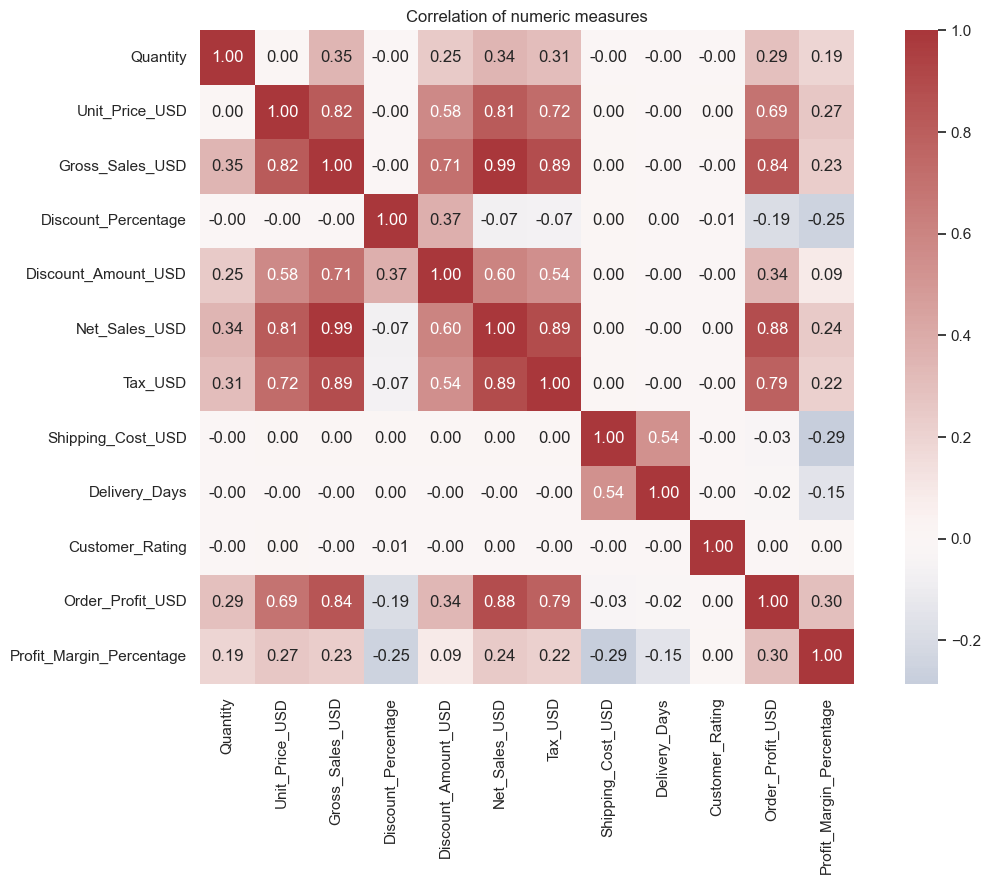

,Quantity,Unit_Price_USD,Gross_Sales_USD,Discount_Percentage,Discount_Amount_USD,Net_Sales_USD,Tax_USD,Shipping_Cost_USD,Delivery_Days,Customer_Rating,Order_Profit_USD,Profit_Margin_Percentage
Quantity,1.00,0.00,0.35,-0.00,0.25,0.34,0.31,-0.00,-0.00,-0.00,0.29,0.19
Unit_Price_USD,0.00,1.00,0.82,-0.00,0.58,0.81,0.72,0.00,-0.00,0.00,0.69,0.27
Gross_Sales_USD,0.35,0.82,1.00,-0.00,0.71,0.99,0.89,0.00,-0.00,-0.00,0.84,0.23
Discount_Percentage,-0.00,-0.00,-0.00,1.00,0.37,-0.07,-0.07,0.00,0.00,-0.01,-0.19,-0.25
Discount_Amount_USD,0.25,0.58,0.71,0.37,1.00,0.60,0.54,0.00,-0.00,-0.00,0.34,0.09
Net_Sales_USD,0.34,0.81,0.99,-0.07,0.60,1.00,0.89,0.00,-0.00,0.00,0.88,0.24
Tax_USD,0.31,0.72,0.89,-0.07,0.54,0.89,1.00,0.00,-0.00,-0.00,0.79,0.22
Shipping_Cost_USD,-0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.54,-0.00,-0.03,-0.29
Delivery_Days,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,-0.00,0.54,1.00,-0.00,-0.02,-0.15
Customer_Rating,-0.00,0.00,-0.00,-0.01,-0.00,0.00,-0.00,-0.00,-0.00,1.00,0.00,0.00


In [10]:
correlation_cols = [c for c in [
    "Quantity", "Unit_Price_USD", "Gross_Sales_USD", "Discount_Percentage",
    "Discount_Amount_USD", "Net_Sales_USD", "Tax_USD", "Shipping_Cost_USD",
    "Delivery_Days", "Customer_Rating", "Order_Profit_USD", "Profit_Margin_Percentage",
] if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]
if len(correlation_cols) >= 2:
    corr = df[correlation_cols].corr(numeric_only=True)
    plt.figure(figsize=(12, 9))
    sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", square=True)
    plt.title("Correlation of numeric measures")
    plt.tight_layout()
    plt.show()
    display(corr)
else:
    print("Not enough numeric measures for a correlation matrix.")